In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import pandas as pd

# sample

x = np.array([100,200,300,400,500]).reshape (-1,1) # Advertising Spending
y = np.array([25,45,65,85,105])  #Sale

print(x)
print(y)

[[100]
 [200]
 [300]
 [400]
 [500]]
[ 25  45  65  85 105]


In [ ]:
# Linear Regression module
model = LinearRegression()
model.fit(x,y)

LinearRegression()

In [ ]:
prediction = model.predict([[y]])
print(prediction)

NameError: name 'model' is not defined

NameError: name 'model' is not defined

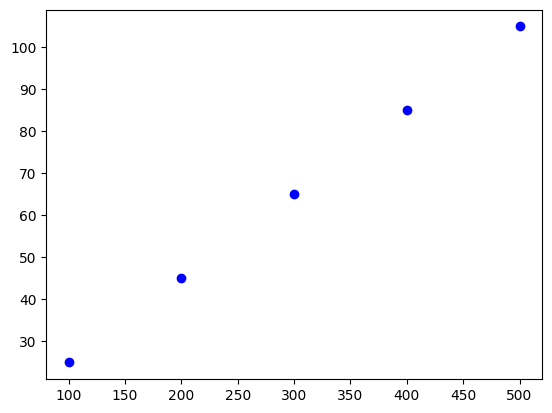

In [ ]:
plt.scatter(x,y, color="blue", label="Actual Sales")
# Calculate predictions for all x values in the original dataset
prediction = model.predict(x)
plt.plot(x, prediction, color="red", label="Model Prediction")
plt.xlabel("Advertising Spending")
plt.ylabel("Sales")
plt.title(" Simple Linear Regression")
plt.legend()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
df = pd.read_csv("Social_Network_Ads.csv")
x= df.iloc[:, :-1].values
y= df.iloc[:,-1].values
df

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
395,46,41000,1
396,51,23000,1
397,50,20000,1
398,36,33000,0


#LOGISTIC REGRESSION


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.25, random_state=0)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state=0)
classifier.fit(x_train, y_train)

LogisticRegression(random_state=0)

In [ ]:
print(classifier.predict(sc.transform([[55,87000]])))

[1]


In [ ]:
y_pred = classifier.predict(x_test)
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

[[0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 1]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 1]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 0]
 [0 0]
 [1 1]
 [1 1]
 [1 1]
 [1 0]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 1]
 [1 1]
 [1 1]]


In [ ]:
#we want to see the performance our our model

from sklearn.metrics import confusion_matrix, accuracy_score
accuracy_score(y_test, y_pred)

# 0.8 is clos to 1 so its good

0.89

In [ ]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[65  3]
 [ 8 24]]


#DECISION TREE


In [ ]:
df = pd.read_csv("Position_Salaries.csv")
a= df.iloc[:, 1:-1].values # Exclude the 'Position' column (index 0)
b= df.iloc[:,-1].values
df

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [ ]:
from sklearn.tree import DecisionTreeRegressor
regressor = DecisionTreeRegressor(random_state=0)
regressor.fit(a,b)

DecisionTreeRegressor(random_state=0)

Text(0, 0.5, 'Salary')

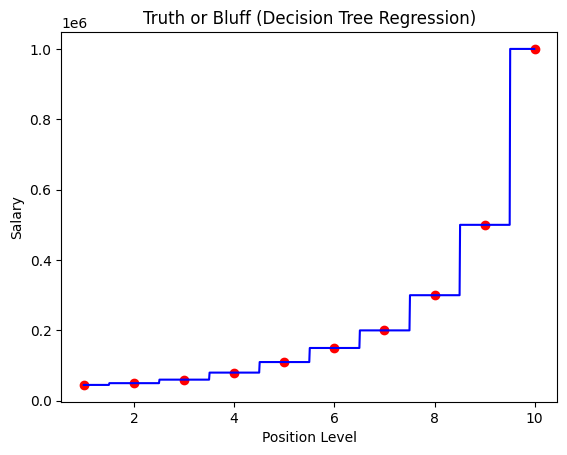

In [ ]:
x_grid = np.arange(a.min(), a.max(), 0.01)
x_grid = x_grid.reshape((len(x_grid),1))
plt.scatter(a,b, color="red")
plt.plot(x_grid, regressor.predict(x_grid), color="blue")
plt.title("Truth or Bluff (Decision Tree Regression)")
plt.xlabel("Position Level")
plt.ylabel("Salary")

#RANDOM FOREST AGRESSOR

In [ ]:
df = pd.read_csv("Position_Salaries.csv")
a= df.iloc[:, 1:-1].values # Exclude the 'Position' column (index 0)
b= df.iloc[:,-1].values
df

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [ ]:
from sklearn.ensemble import RandomForestRegressor
regressor = RandomForestRegressor(n_estimators=10, random_state=0)
regressor.fit(a,b)

RandomForestRegressor(n_estimators=10, random_state=0)

In [ ]:
regressor.predict([[6.5]])

array([167000.])

Text(0, 0.5, 'Salary')

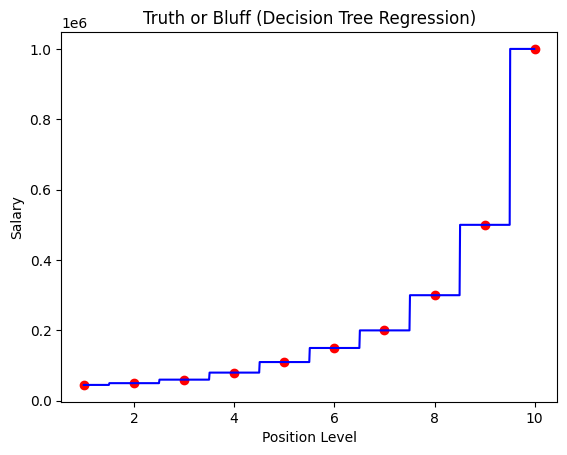

In [ ]:
x_grid = np.arange(a.min(), a.max(), 0.01)
x_grid = x_grid.reshape((len(x_grid),1))
plt.scatter(a,b, color="red")
plt.plot(x_grid, regressor.predict(x_grid), color="blue")
plt.title("Truth or Bluff (Decision Tree Regression)")
plt.xlabel("Position Level")
plt.ylabel("Salary")

In [ ]:
df = pd.read_csv("Social_Network_Ads.csv")
x= df.iloc[:, :-1].values
y= df.iloc[:,-1].values
df

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
395,46,41000,1
396,51,23000,1
397,50,20000,1
398,36,33000,0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(x,y, test_size=0.3, random_state=0)

In [ ]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [ ]:
from sklearn.svm import SVC

classifier = SVC(kernel="linear", random_state=0)
classifier.fit(X_train, y_train)

SVC(kernel='linear', random_state=0)

In [ ]:
y_pred = classifier.predict(X_test)
accuracy_score(y_test, y_pred)

0.8666666666666667

In [ ]:
confusion_matrix(y_test, y_pred)

array([[75,  4],
       [12, 29]])

#LOGISTIC REGRESSION w Titanic Dataset

In [ ]:
df = pd.read_csv("titanic.csv")
a= df.iloc[:,-3].values #Last is 12
b= df.iloc[:,5].values
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [ ]:
print(a[:5]) # Display the first 5 elements of the NumPy array

[ 7.25   71.2833  7.925  53.1     8.05  ]


In [ ]:
print(b[:5]) # Display the first 5 elements of the NumPy array

[22. 38. 26. 35. 35.]


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.25, random_state=0)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state=0)
classifier.fit(x_train, y_train)

LogisticRegression(random_state=0)

In [ ]:
print(classifier.predict(sc.transform([[7.25,22]])))

[0]


In [ ]:
prod = classifier.predict(x_test)
cm = confusion_matrix(y_test, prod)
print(cm)
accuracy_score(y_test, prod)

[[65  3]
 [ 8 24]]


0.89

In [ ]:
result_df = pd.DataFrame({'Actual': y_test, 'Predicted': prod})
result_df

,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
95,1,0
96,0,0
97,1,0
98,1,1


#Passenger Survival

In [ ]:
df = pd.read_csv("titanic.csv")
a= df.iloc[:,-3].values #Last is 12
b= df.iloc[:,5].values
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Initialize and train the Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=0)
rf_classifier.fit(x_train, y_train)

# Predict on the test set
y_pred_rf = rf_classifier.predict(x_test)

# Evaluate the Random Forest model
print("Random Forest Classifier Results:")
print(f"Accuracy:' {accuracy_score(y_test, y_pred_rf):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Classifier Results:
Accuracy:' 0.8386
Confusion Matrix:
[[124  15]
 [ 21  63]]


### Data Preparation for Titanic Dataset

Following the plan, let's prepare the Titanic dataset for model training.

In [ ]:
# Step 1: Select Features and Target
# We'll use 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', and 'Fare' as features
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked'] # Include Embarked for encoding
target = 'Survived'

x = df[features]
y = df[target]

print("Original features shape:", x.shape)
print("Original target shape:", y.shape)
print("\nFeatures with missing values:\n", x.isnull().sum())

Original features shape: (891, 7)
Original target shape: (891,)

Features with missing values:
 Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


### Handle Missing Values and Encode Categorical Features

In [ ]:
# Step 2 & 3: Handle Missing Values and Encode Categorical Features

# Handle missing 'Age' values by imputing with the median
x['Age'].fillna(x['Age'].median(), inplace=True)

# Handle missing 'Embarked' values by imputing with the mode and then one-hot encode
# First, impute
x['Embarked'].fillna(x['Embarked'].mode()[0], inplace=True)
# Then, one-hot encode 'Sex' and 'Embarked'
x = pd.get_dummies(x, columns=['Sex', 'Embarked'], drop_first=True)


# Handle missing 'Fare' values (if any) - using median imputation as an example
x['Fare'].fillna(x['Fare'].median(), inplace=True)


print("\nFeatures after handling missing values and encoding:\n", x.isnull().sum())
print("\nProcessed features head:\n", x.head())


Features after handling missing values and encoding:
 Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_male      0
Embarked_Q    0
Embarked_S    0
dtype: int64

Processed features head:
    Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  Embarked_S
0       3  22.0      1      0   7.2500      True       False        True
1       1  38.0      1      0  71.2833     False       False       False
2       3  26.0      0      0   7.9250     False       False        True
3       1  35.0      1      0  53.1000     False       False        True
4       3  35.0      0      0   8.0500      True       False        True


/tmp/ipython-input-3510277188.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  x['Age'].fillna(x['Age'].median(), inplace=True)
/tmp/ipython-input-3510277188.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x['Age'].fillna(x['Age'].median(), inplace=True)
/tmp/ipython-input-3510277188.py:8: FutureWarning: A value is trying to be set on a

### Support Vector Machine (SVM) Classifier

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Initialize and train the SVM Classifier with RBF kernel
svm_classifier = SVC(kernel='rbf', random_state=0)
svm_classifier.fit(x_train, y_train)

# Predict on the test set
y_pred_svm = svm_classifier.predict(x_test)

# Evaluate the SVM model
print("Support Vector Machine (SVM) Classifier Results (RBF Kernel):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

Support Vector Machine (SVM) Classifier Results (RBF Kernel):
Accuracy: 0.8072
Confusion Matrix:
[[121  18]
 [ 25  59]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       139
           1       0.77      0.70      0.73        84

    accuracy                           0.81       223
   macro avg       0.80      0.79      0.79       223
weighted avg       0.81      0.81      0.81       223



### Classification Report for Random Forest (for comparison)

In [ ]:
from sklearn.metrics import classification_report

# Assuming y_test and y_pred_rf from the Random Forest cell are available
print("Random Forest Classifier Classification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Classifier Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.89      0.87       139
           1       0.81      0.75      0.78        84

    accuracy                           0.84       223
   macro avg       0.83      0.82      0.83       223
weighted avg       0.84      0.84      0.84       223



### Split Data

In [ ]:
# Step 4: Split Data
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)

print("\nx_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


x_train shape: (668, 8)
x_test shape: (223, 8)
y_train shape: (668,)
y_test shape: (223,)


### Scale Features (Optional but Recommended)

In [ ]:
# Step 5: Scale Features
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

print("\nx_train after scaling head:\n", x_train[:5])
print("x_test after scaling head:\n", x_test[:5])


x_train after scaling head:
 [[ 0.83012938 -0.11727262 -0.46037161 -0.47720996 -0.48380773  0.72705166
  -0.31414043  0.59809997]
 [ 0.83012938 -0.96500423  2.98532288  1.95619654 -0.48323058 -1.37541808
  -0.31414043  0.59809997]
 [ 0.83012938  0.0368604   0.40105202 -0.47720996 -0.32165051  0.72705166
  -0.31414043  0.59809997]
 [ 0.83012938 -0.57967168 -0.46037161 -0.47720996 -0.49657206  0.72705166
  -0.31414043  0.59809997]
 [-0.36497068  1.19285805 -0.46037161 -0.47720996 -0.37303989 -1.37541808
  -0.31414043  0.59809997]]
x_test after scaling head:
 [[ 0.83012938 -0.11727262 -0.46037161 -0.47720996 -0.35409895  0.72705166
  -0.31414043 -1.67196129]
 [ 0.83012938 -0.11727262 -0.46037161 -0.47720996 -0.49064251  0.72705166
  -0.31414043  0.59809997]
 [ 0.83012938 -1.73566933  2.98532288  0.73949329 -0.06420947  0.72705166
   3.1832897  -1.67196129]
 [-1.56007074 -0.11727262  0.40105202 -0.47720996  2.25613578 -1.37541808
  -0.31414043 -1.67196129]
 [ 0.83012938 -0.04020611 -0.460

Now, let's implement the XGBoost Classifier. XGBoost is a powerful gradient boosting library.

In [ ]:
# You might need to install xgboost if you haven't already
# !pip install xgboost

from xgboost import XGBClassifier

# Initialize and train the XGBoost Classifier
# Using use_label_encoder=False to avoid a deprecation warning
xgb_classifier = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=0)
xgb_classifier.fit(x_train, y_train)

# Predict on the test set
y_pred_xgb = xgb_classifier.predict(x_test)

# Evaluate the XGBoost model
print("\nXGBoost Classifier Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))


XGBoost Classifier Results:
Accuracy: 0.8341
Confusion Matrix:
[[119  20]
 [ 17  67]]


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:183: UserWarning: [09:00:40] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


### Visualization 1: Confusion Matrix Heatmap (Random Forest Model)

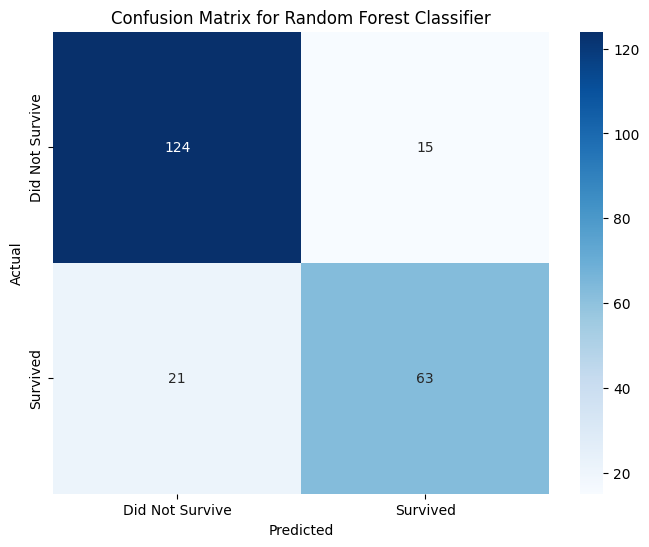

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Assuming y_test and y_pred_rf are available from the Random Forest evaluation cell

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Did Not Survive', 'Survived'], yticklabels=['Did Not Survive', 'Survived'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Random Forest Classifier')
plt.show()

### Visualization 2: Survival Rate by Gender

/tmp/ipython-input-4114989993.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=survival_by_sex, palette='viridis')


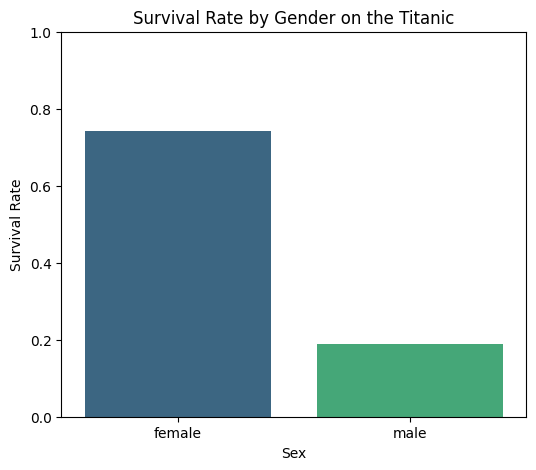

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming df is the original Titanic DataFrame loaded in a previous cell

# Calculate survival rate by Sex
survival_by_sex = df.groupby('Sex')['Survived'].mean().reset_index()

plt.figure(figsize=(6, 5))
sns.barplot(x='Sex', y='Survived', data=survival_by_sex, palette='viridis')
plt.ylabel('Survival Rate')
plt.title('Survival Rate by Gender on the Titanic')
plt.ylim(0, 1) # Survival rate is between 0 and 1
plt.show()

#Use Cancer Dataset using any machine learning model, to figure out type of cancer

In [ ]:
df = pd.read_csv("Cancer_Data.csv")
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [ ]:
#0.9 accuracy

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
classifier = KNeighborsClassifier(n_neighbors = 5, metric = 'minkowski', p = 2)
classifier.fit(X_train, y_train)

#hire neighbors

ValueError: Found input variables with inconsistent numbers of samples: [280, 668]

In [ ]:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train, y_train)

#Split, Scale and Add to the model

